# Palate held-out distribution reconstruction

This notebook evaluates strict leave-one-stage-out (LOSO) palate models at E13.5 and E14.0. Each model starts from the observed E12.5 cells and predicts the omitted stage without using that stage during trajectory or cross-modal map training.

The quantitative scores are calculated in **normalized RNA PCA40 and ATAC LSI15**, never in UMAP. UMAP is used only to compare prediction and truth in a shared visual frame.

## Required results

Run balanced and unbalanced strict LOSO training for both middle stages first:

```bash
python -m examples.palate.train_balanced_loso --held-out-stage E13.5 --output outputs/palate-balanced-loo-e13.5
python -m examples.palate.train_unbalanced_loso --held-out-stage E13.5 --output outputs/palate-unbalanced-loo-e13.5
python -m examples.palate.train_balanced_loso --held-out-stage E14.0 --output outputs/palate-balanced-loo-e14.0
python -m examples.palate.train_unbalanced_loso --held-out-stage E14.0 --output outputs/palate-unbalanced-loo-e14.0
```

Each output directory must contain `result.json` and `heldout_prediction.npz`. The supplied runs use the strict held-out FiLM map for the corresponding stage.

In [1]:
from pathlib import Path
import json

import anndata as ad
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.neighbors import KNeighborsRegressor

from coati.downstream import evaluate_paired_distributions

%matplotlib inline
plt.rcParams.update({"font.family": "Arial", "font.size": 11})

project_dir = next((p for p in (Path.cwd(), *Path.cwd().parents)
                    if (p / "pyproject.toml").exists() and (p / "src/coati").is_dir()), None)
if project_dir is None:
    raise FileNotFoundError("Run this notebook inside a COATI checkout.")

In [2]:
data_path = project_dir / "examples/palate/data/palate_embeddings.h5ad"
cells = ad.read_h5ad(data_path)

def locate_run(name):
    candidates = [project_dir / "outputs" / name, project_dir / "outputs" / f"{name}-mps"]
    for directory in candidates:
        if (directory / "result.json").exists() and (directory / "heldout_prediction.npz").exists():
            return directory
    raise FileNotFoundError(f"No completed run found for {name}: {candidates}")

run_specs = [
    ("Balanced", "E13.5", locate_run("palate-balanced-loo-e13.5")),
    ("Unbalanced", "E13.5", locate_run("palate-unbalanced-loo-e13.5")),
    ("Balanced", "E14.0", locate_run("palate-balanced-loo-e14.0")),
    ("Unbalanced", "E14.0", locate_run("palate-unbalanced-loo-e14.0")),
]

runs = {}
for model, stage, directory in run_specs:
    metadata = json.loads((directory / "result.json").read_text())
    with np.load(directory / "heldout_prediction.npz", allow_pickle=False) as archive:
        prediction = {key: np.asarray(archive[key]) for key in archive.files}
    runs[(model, stage)] = {"metadata": metadata, "prediction": prediction}

[(model, stage, runs[(model, stage)]["prediction"]["primary"].shape)
 for model, stage, _ in run_specs]

[('Balanced', 'E13.5', (2570, 40)),
 ('Unbalanced', 'E13.5', (2570, 40)),
 ('Balanced', 'E14.0', (2570, 40)),
 ('Unbalanced', 'E14.0', (2570, 40))]

## Six distribution scores

Three metrics are calculated independently in RNA and ATAC:

- **Support recall ↑** measures how much normalized predicted mass covers the local neighborhoods of real held-out cells.
- **Sinkhorn-based $W_2$ ↓** reports $\sqrt{2S_\varepsilon}$ from at most 512 weighted microclusters, with debiased Sinkhorn divergence, $p=2$, and blur 0.05.
- **Composition similarity ↑** transfers cell types by 1-nearest-neighbor matching in the corresponding modality and reports $1-\sqrt{\mathrm{JSD}_2}$.

Balanced predictions use equal particle weights. Unbalanced predictions use their normalized native masses. These metrics compare distribution shape and composition, not total population size.

In [3]:
records = []
for model, stage, _ in run_specs:
    item = runs[(model, stage)]
    metadata = item["metadata"]
    prediction = item["prediction"]
    held_out = np.isclose(cells.obs["time"].to_numpy(dtype=float), float(prediction["time"]))
    labels = cells.obs.loc[held_out, "celltype"].astype(str).to_numpy()

    paired = evaluate_paired_distributions(
        prediction["primary"] / metadata["primary_scale"],
        np.asarray(cells.obsm["X_pca"][held_out]) / metadata["primary_scale"],
        labels,
        prediction["secondary"] / metadata["secondary_scale"],
        np.asarray(cells.obsm["X_atac"][held_out]) / metadata["secondary_scale"],
        labels,
        log_weights=prediction.get("log_weights"),
        support_k=15,
        max_clusters=512,
        sinkhorn_blur=0.05,
        unknown_label="unknown",
    )
    scores = {key.replace("primary_", "rna_").replace("secondary_", "atac_"): value
              for key, value in paired.items()}
    records.append({"Model": model, "Held out": stage, **scores})

metrics = pd.DataFrame(records)
score_columns = [
    "Model", "Held out", "rna_support_recall", "atac_support_recall",
    "rna_sinkhorn_w2", "atac_sinkhorn_w2",
    "rna_composition_similarity", "atac_composition_similarity",
]
display(metrics[score_columns].style.format(precision=4))

,Model,Held out,rna_support_recall,atac_support_recall,rna_sinkhorn_w2,atac_sinkhorn_w2,rna_composition_similarity,atac_composition_similarity
0,Balanced,E13.5,0.8675,0.7353,0.4086,0.4757,0.9264,0.9202
1,Unbalanced,E13.5,0.8852,0.7543,0.3565,0.4530,0.9544,0.9066
2,Balanced,E14.0,0.8585,0.6871,0.3994,0.4492,0.8645,0.8751
3,Unbalanced,E14.0,0.8765,0.7768,0.3956,0.3910,0.8841,0.8892


## Prediction and truth in shared global UMAPs

Use the global RNA and ATAC atlas coordinates stored in the supplied AnnData. A distance-weighted 15-nearest-neighbor regressor is fitted once from each observed input space to its corresponding atlas coordinates, then projects all four predictions.

No UMAP is fitted to a prediction, no serialized UMAP model is required, and no metric is calculated in UMAP. The background in every panel is the same complete observed atlas.

In [4]:
primary_scale = runs[("Balanced", "E13.5")]["metadata"]["primary_scale"]
secondary_scale = runs[("Balanced", "E13.5")]["metadata"]["secondary_scale"]
reference = {
    "RNA": np.asarray(cells.obsm["X_pca"], dtype=np.float32) / primary_scale,
    "ATAC": np.asarray(cells.obsm["X_atac"], dtype=np.float32) / secondary_scale,
}

reference_umap = {
    "RNA": np.asarray(cells.obsm["X_umap"], dtype=np.float32),
    "ATAC": np.asarray(cells.obsm["X_atac_umap"], dtype=np.float32),
}
prediction_umap = {"RNA": {}, "ATAC": {}}
for modality, prediction_key, scale in ("RNA", "primary", primary_scale), ("ATAC", "secondary", secondary_scale):
    atlas_projection = KNeighborsRegressor(
        n_neighbors=15, weights="distance", n_jobs=-1,
    ).fit(reference[modality], reference_umap[modality])
    keys = list(runs)
    arrays = [runs[key]["prediction"][prediction_key] / scale for key in keys]
    lengths = [len(array) for array in arrays]
    transformed = np.asarray(atlas_projection.predict(np.concatenate(arrays)))
    pieces = np.split(transformed, np.cumsum(lengths)[:-1])
    prediction_umap[modality].update(dict(zip(keys, pieces)))

print({modality: coordinates.shape for modality, coordinates in reference_umap.items()})

{'RNA': (19833, 2), 'ATAC': (19833, 2)}


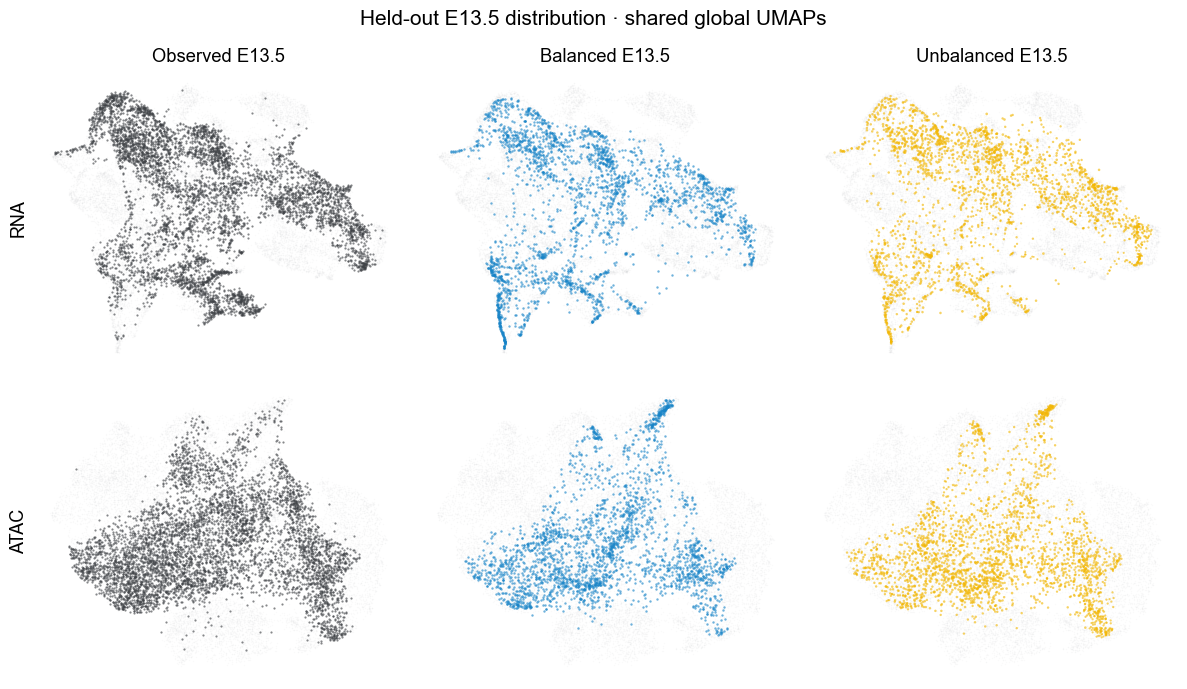

In [5]:
def particle_sizes(prediction):
    if "log_weights" not in prediction:
        return 3.0
    values = np.asarray(prediction["log_weights"], dtype=float).reshape(-1)
    weights = np.exp(values - values.max())
    weights /= weights.sum()
    return np.clip(3.0 * np.sqrt(weights * len(weights)), 0.8, 9.0)

def plot_held_out_stage(stage):
    stage_time = {"E13.5": 1.0, "E14.0": 1.5}[stage]
    observed = np.isclose(cells.obs["time"].to_numpy(dtype=float), stage_time)
    columns = [("Observed", "#3F4246"), ("Balanced", "#1683C7"),
               ("Unbalanced", "#F2B705")]
    fig, axes = plt.subplots(2, 3, figsize=(12.0, 7.0))
    for row, modality in enumerate(("RNA", "ATAC")):
        atlas = reference_umap[modality]
        for column, (model, color) in enumerate(columns):
            ax = axes[row, column]
            ax.scatter(atlas[:, 0], atlas[:, 1], s=1.0, color="#D8DADD",
                       alpha=.12, linewidths=0, rasterized=True)
            if model == "Observed":
                coordinates = atlas[observed]
                sizes = 2.5
            else:
                item = runs[(model, stage)]
                coordinates = prediction_umap[modality][(model, stage)]
                sizes = particle_sizes(item["prediction"])
            ax.scatter(coordinates[:, 0], coordinates[:, 1], s=sizes, color=color,
                       alpha=.62, linewidths=0, rasterized=True)
            ax.set_title(f"{model} {stage}" if row == 0 else "")
            ax.set_ylabel(modality if column == 0 else "", fontsize=13)
            ax.set_xticks([])
            ax.set_yticks([])
            for spine in ax.spines.values():
                spine.set_visible(False)
    fig.suptitle(f"Held-out {stage} distribution · shared global UMAPs", fontsize=15)
    fig.tight_layout()
    return fig

plot_held_out_stage("E13.5");

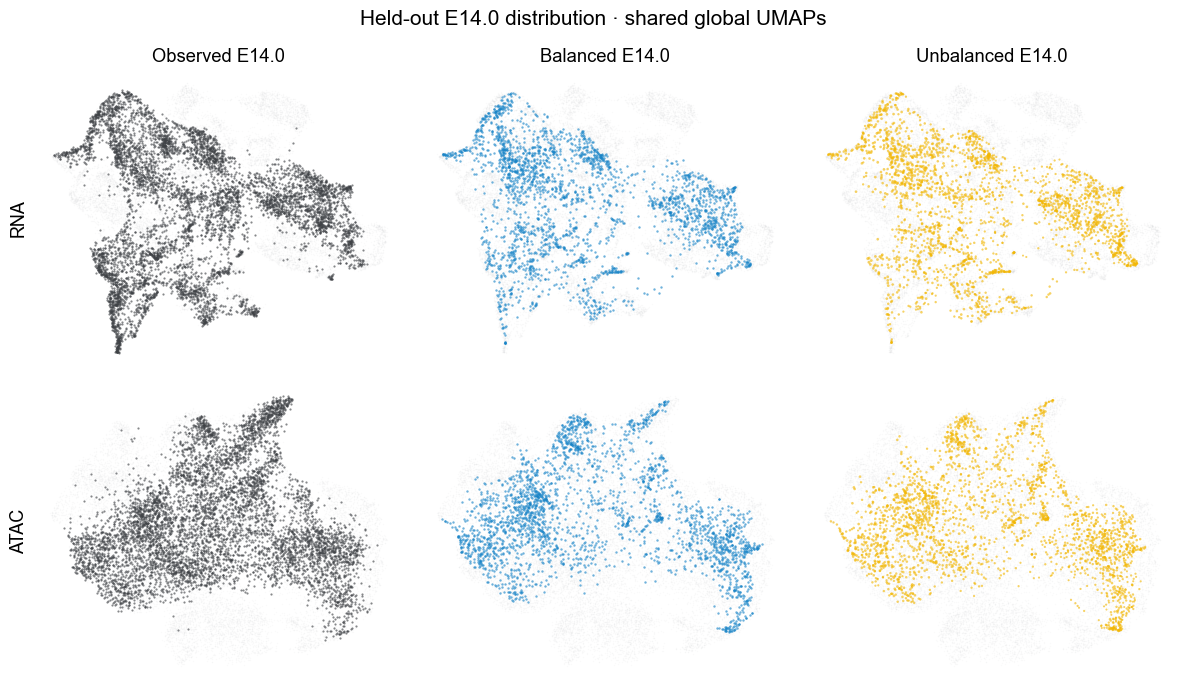

In [6]:
plot_held_out_stage("E14.0");

The UMAP panels are qualitative support checks. Broad visual overlap can coexist with local density or cell-type composition errors, so the normalized PCA/LSI-space scores remain the primary evaluation.